# Datathon IV - MLOps

Here is the updated table with an additional column to differentiate between positive and negative aspects, and a note that the total points are 10.

| **Activity**                                     | **Points** | **Evaluation** |
|--------------------------------------------------|------------|----------------|
| **Pipeline and MLFlow Tasks**                    |**Total: 7**|                 |
| Create a Scikit-Learn Pipeline                   | 1.0        | ✅              |
| Launch a local MLflow server                     | 0.5        | ✅              |
| Train and Evaluate the model inside a MLFlow Run | 1.0        | ✅              |
| Log the model and the metrics using MLflow       | 1.0        | ✅              |
| Register the model in MLflow                     | 1.0        | ✅              |
| Deploy the model to a REST API                   | 1.0        | ✅              |
| Make predictions using the REST API              | 1.0        | ✅              |
| Upload the predictions to the database           | 0.5        | ✅              |
| **Code and Documentation**                       |**Total: 1**|                 |
| Code legibility                                  | 0.5        | ✅              |
| Notebook documentation (titles, subtitles, text) | 0.5        | ✅              |
| **GIT Repository**                               |**Total: 3**|                 |
| Adding a complete README.md file                 | 1.0        | ✅              |
| Adding a .gitignore and requirements.txt file    | 0.5        | ✅              |
| Using branches for development                   | 0.5        | ✅              |
| **Bonus Points**                                 | **Bonus**           |                 |
| Any other activity (e.g., GridSearch)            | *Bonus*    | ✅              |
| Trying with other products                       | *Bonus*    | ✅              |
| **Negative Evaluations**                         |**Total: -6.5**|                 |
| Pushing data to the repository                   | -1.0          | ❌              |
| Pushing passwords or sensitive information       | -3.0        | ❌              |
| Pushing files generated by MLFlow (e.g., `mlruns`) | -1.0        | ❌              |
| Missing standard Python files (e.g., `requirements.txt`, `.gitignore`) | -0.5 | ❌              |
| A bad-looking README.md file                     | -1.0          | ❌              |

### Notes:
- **Total Points: 10** (excluding bonuses and negative impacts). 
- Bonus points can enhance the score but do not contribute to exceeding the maximum of 10 points. 
- Negative practices result in deductions.

# Data request, processing and modelling pipeline

Here we will connect to the database and process the raw files to build the dataset before creating our model. This notebook represents a quick workflow of the steps observed in the previous notebooks with the idea of building a pipeline to automatize all the workd. To do that, this pipeline will: 

- Connect to the database
- Add time, weather information and "festivo" days information
- Process variables (codification, scaling) --> As we saw in the EDA analysis, there are no "impossible" selling amount values, so we will not do outliers detection
- Split data into training and test datasets
- Test several models (regression models) and parameters (data splitting proportion, hiperparameters...)
- Track modelling metrics (RMSE, etc...) in MLflow

In [1]:
# Avoid unnecessary warnings

import warnings
warnings.filterwarnings('ignore')

## 1. Prepare the data

First step always is data loading. CSV are provided and can be replicated from the previows lesson. CSVs contains data for the PRODUCT_ID 3960.

- 👉 Load train and test datasets.
- 👉 Filter dataset for producto "3960" in BOLLERIA category.
- 👉 Set "fecha_venta" as index column.
- 👉 Sort the data by "fecha_venta" column.
- 👉 Show the first 5 rows of the train dataset.

### 1.1. Load the data


Load the sensitive information within environmental variables that will be not shown as .env file is included in .gitignore

In [2]:
import os
from dotenv import load_dotenv

# Load variables from the .env file in the project root
load_dotenv()

USERNAME = os.environ["DB_USERNAME"]
PASSWORD = os.environ["DB_PASSWORD"]
DB_HOST = os.environ["DB_HOST"]
DB_PORT = int(os.environ["DB_PORT"])
DB_NAME = os.environ["DB_NAME"]

LOCATION = (
    float(os.environ["SHOP_LAT"]),
    float(os.environ["SHOP_LON"]),
)

MLFLOW_TRACKING_URI = os.environ["MLFLOW_TRACKING_URI"]
MLFLOW_EXPERIMENT_NAME = os.environ["MLFLOW_EXPERIMENT_NAME"]

In [3]:
required_vars = [
    "DB_USERNAME", "DB_PASSWORD", "DB_HOST", "DB_PORT", "DB_NAME",
    "SHOP_LAT", "SHOP_LON",
]

missing = [var for var in required_vars if var not in os.environ]
if missing:
    raise EnvironmentError(
        f"Missing required environment variables: {', '.join(missing)}. "
        "Check that your .env file exists and is loaded."
    )

Load the data

In [4]:
import os
import pandas as pd
import sqlalchemy as sa


class DatabaseConnection:
    def __init__(
        self,
        username: str,
        password: str,
        database: str | None = None,
        host: str | None = None,
        port: int | None = None,
        dialect: str = "mysql",
        driver: str = "pymysql",
    ) -> None:
        database = database or os.environ["DB_NAME"]
        host = host or os.environ["DB_HOST"]
        port = port or int(os.environ["DB_PORT"])

        connection_string = (
            f"{dialect}+{driver}://{username}:{password}"
            f"@{host}:{port}/{database}"
        )

        self.engine = sa.create_engine(connection_string)

    def query_to_df(self, query: str) -> pd.DataFrame:
        with self.engine.connect() as conn:
            result = conn.execute(sa.text(query))
            return pd.DataFrame(result.fetchall(), columns=result.keys())

    def insert_dataframe(self, df: pd.DataFrame, table_name: str) -> None:
        df.to_sql(table_name, self.engine, if_exists="replace", index=False)

    def check_connection(self) -> bool:
        try:
            with self.engine.connect() as conn:
                conn.execute(sa.text("SELECT 1"))
            return True
        except Exception as exc:
            print(f"Connection failed: {exc}")
            return False

    def close(self) -> None:
        self.engine.dispose()

In [5]:
from sqlalchemy import inspect

database = DatabaseConnection(USERNAME, PASSWORD)

# Create inspector
inspector = inspect(database.engine)

# Get all tables
tables = inspector.get_table_names()

print("Tables available in the database:")
for table in tables:
    print(f"- {table}")

Tables available in the database:
- Materials_Prediction_Group_irampardo
- Prediction_3960_latest_irampardo
- articulos_top
- calendario_completo
- calendario_dias
- raw_calendario
- raw_pedidos
- raw_ventas
- ventas_diarias


In [6]:
from sqlalchemy import inspect, text

database = DatabaseConnection(USERNAME, PASSWORD)
inspector = inspect(database.engine)

tables_to_check = ["ventas_diarias", "raw_pedidos"]

for table in tables_to_check:

    print(f"\n{'='*50}")
    print(f"TABLE: {table}")
    print(f"{'='*50}")

    # 1. Get column names and types
    columns = inspector.get_columns(table)

    for col in columns:
        print(f"{col['name']:<25} {col['type']}")

    # 2. Identify date/datetime columns
    date_columns = [
        col["name"]
        for col in columns
        if "DATE" in str(col["type"]).upper()
    ]

    # 3. Get maximum date
    for date_col in date_columns:

        query = f"""
        SELECT MAX(`{date_col}`) AS latest_date
        FROM `{table}`;
        """

        result = database.query_to_df(query)

        print(f"\nLatest date ({date_col}): {result['latest_date'].iloc[0]}")


TABLE: ventas_diarias
familia                   VARCHAR(255)
tipo                      VARCHAR(255)
fechaVenta                DATE
festivo                   VARCHAR(255)
articulo                  VARCHAR(255)
precio                    DOUBLE
orden_articulo_familia    BIGINT
in_fecha_estudio          VARCHAR(1)
cantidad                  DOUBLE
importe                   DOUBLE

Latest date (fechaVenta): 2023-05-18

TABLE: raw_pedidos
Tipo                      VARCHAR(255)
Fecha                     DATE
Articulo                  VARCHAR(255)
Cantidad                  FLOAT
Precio                    FLOAT
Importe                   FLOAT

Latest date (Fecha): 2023-05-18


In [ ]:
query = """
    SELECT familia,
    articulo,
    fechaVenta AS fecha_venta,
    festivo,
    precio,
    cantidad,
    importe,
    orden_articulo_familia

    FROM ventas_diarias
"""

database = DatabaseConnection(USERNAME, PASSWORD)


df = database.query_to_df(query)
df["fecha_venta"] = pd.to_datetime(df["fecha_venta"])
df["articulo"] = df["articulo"].astype(int)
df.head()

In [ ]:
print("First date:", df["fecha_venta"].min())
print("Last date:", df["fecha_venta"].max())
print("Total records:", len(df))

First date: 2017-01-01 00:00:00
Last date: 2023-05-18 00:00:00
Total records: 177589


### 1.2. Filter by Item 

We selected the PRODUCT_ID 3960, but we can select any other item.

In [ ]:
PRODUCT_FAMILY = "BOLLERIA"
PRODUCT_ID = 3960


item_df = df.copy()
item_df = item_df[item_df["articulo"] == PRODUCT_ID].copy()

item_df["fecha_venta"] = pd.to_datetime(item_df["fecha_venta"])
item_df = item_df.sort_values("fecha_venta").reset_index(drop=True)

# Aggregate any duplicate product-date rows before reindexing.
item_df = (
    item_df
    .groupby("fecha_venta", as_index=False)
    .agg({
        "cantidad": "sum",
        "importe": "sum",
        "precio": "mean",
        "festivo": "first",
        "familia": "first",
        "articulo": "first",
    })
    .sort_values("fecha_venta")
    .reset_index(drop=True)
)

# Create one row per calendar day.
full_dates = pd.DataFrame({
    "fecha_venta": pd.date_range(
        start=item_df["fecha_venta"].min(),
        end=item_df["fecha_venta"].max(),
        freq="D"
    )
})

item_df = (
    full_dates
    .merge(item_df, on="fecha_venta", how="left")
    .sort_values("fecha_venta")
    .reset_index(drop=True)
)

item_df["cantidad"] = item_df["cantidad"].fillna(0)
item_df["is_available"] = item_df["cantidad"].notna().astype(int)

assert item_df["fecha_venta"].is_unique
assert item_df["fecha_venta"].is_monotonic_increasing
assert (
    item_df["fecha_venta"].diff().dropna() == pd.Timedelta(days=1)
).all()

item_df.head()

,fecha_venta,cantidad,importe,precio,festivo,familia,articulo,is_available
0,2017-01-01,132.0,234.035995,1.773,Año Nuevo,BOLLERIA,3960.0,1
1,2017-01-02,207.0,367.011002,1.773,NaN,BOLLERIA,3960.0,1
2,2017-01-03,228.0,404.244000,1.773,NaN,BOLLERIA,3960.0,1
3,2017-01-04,171.0,303.182992,1.773,NaN,BOLLERIA,3960.0,1
4,2017-01-05,213.0,377.648996,1.773,NaN,BOLLERIA,3960.0,1


### 1.3. Transformers of the data

#### 1.3.1 Calendar Transformer

The calendar transformer will perform the following operations:

- 👉 Extract the day
- 👉 Extract the month
- 👉 Extract the year
- 👉 Extract the day of the week
- 👉 Extract the weekend (true/false)
- 👉 Extract the holiday (true/false)

First we add the `day`, `month`, `year`, `dayofweek` and `weekend` columns.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

def add_calendar_features(df, date_col="fecha_venta"):
    df = df.copy()
    date = pd.to_datetime(df[date_col])

    df["day_of_week"] = date.dt.dayofweek
    df["day_of_month"] = date.dt.day
    df["month"] = date.dt.month
    df["is_weekend"] = (date.dt.dayofweek >= 5).astype(int)

    # Bakery demand often has strong weekday effects
    df["is_friday"] = (date.dt.dayofweek == 4).astype(int)
    df["is_saturday"] = (date.dt.dayofweek == 5).astype(int)
    df["is_sunday"] = (date.dt.dayofweek == 6).astype(int)

    # Payday / month-boundary effects
    df["is_month_start"] = date.dt.is_month_start.astype(int)
    df["is_month_end"] = date.dt.is_month_end.astype(int)
    df["is_near_payday"] = df["day_of_month"].isin(
        [1, 2, 3, 15, 16, 17]
    ).astype(int)

    return df


def add_holiday_features(df, holiday_col="festivo"):
    df = df.copy()

    df["is_holiday"] = df[holiday_col].notna().astype(int)

    # Neighbouring days can have different demand patterns
    df["is_day_before_holiday"] = (
        df["is_holiday"].shift(-1, fill_value=0)
    ).astype(int)

    df["is_day_after_holiday"] = (
        df["is_holiday"].shift(1, fill_value=0)
    ).astype(int)

    return df


class CalendarTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, date_col="fecha_venta", holiday_col="festivo"):
        self.date_col = date_col
        self.holiday_col = holiday_col

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = add_calendar_features(X, self.date_col)
        X = add_holiday_features(X, self.holiday_col)
        return X

Then we add the `holiday` column.

In [ ]:
def add_holiday_column(df: pd.DataFrame, holiday_column_name: str = "festivo") -> pd.DataFrame:
    df["isHoliday"]  = ~df[holiday_column_name].isna()
    return df

item_df_tmp = item_df.copy()
add_holiday_column(item_df_tmp).head()

,fecha_venta,cantidad,importe,precio,festivo,familia,articulo,is_available,isHoliday
0,2017-01-01,132.0,234.035995,1.773,Año Nuevo,BOLLERIA,3960.0,1,True
1,2017-01-02,207.0,367.011002,1.773,NaN,BOLLERIA,3960.0,1,False
2,2017-01-03,228.0,404.244000,1.773,NaN,BOLLERIA,3960.0,1,False
3,2017-01-04,171.0,303.182992,1.773,NaN,BOLLERIA,3960.0,1,False
4,2017-01-05,213.0,377.648996,1.773,NaN,BOLLERIA,3960.0,1,False


Finally we create the `CalendarTransformer` class.

Let's transform the data.

In [ ]:
item_df_tmp = item_df.copy()

calendar_transformer = CalendarTransformer()

calendar_transformer.fit(item_df_tmp)

calendar_transformer.transform(item_df_tmp).head()

,fecha_venta,cantidad,importe,precio,festivo,familia,articulo,is_available,day_of_week,day_of_month,...,is_weekend,is_friday,is_saturday,is_sunday,is_month_start,is_month_end,is_near_payday,is_holiday,is_day_before_holiday,is_day_after_holiday
0,2017-01-01,132.0,234.035995,1.773,Año Nuevo,BOLLERIA,3960.0,1,6,1,...,1,0,0,1,1,0,1,1,0,0
1,2017-01-02,207.0,367.011002,1.773,NaN,BOLLERIA,3960.0,1,0,2,...,0,0,0,0,0,0,1,0,0,1
2,2017-01-03,228.0,404.244000,1.773,NaN,BOLLERIA,3960.0,1,1,3,...,0,0,0,0,0,0,1,0,0,0
3,2017-01-04,171.0,303.182992,1.773,NaN,BOLLERIA,3960.0,1,2,4,...,0,0,0,0,0,0,0,0,0,0
4,2017-01-05,213.0,377.648996,1.773,NaN,BOLLERIA,3960.0,1,3,5,...,0,0,0,0,0,0,0,0,1,0


#### 1.3.2. Weather Transformer

We use the meteostat API to get the weather data. The weather transformer will perform the following operations:

- 👉 Add the weather conditions for the dates in the dataframe
- 👉 Add a `rain` column (true/false)

First we create a function to fetch the weather dataframe.

In [ ]:
import pandas as pd
import meteostat as ms
from datetime import datetime

def get_weather_data(
    start: datetime,
    end: datetime,
    location: tuple[float, float]
) -> pd.DataFrame:

    # Define shop location
    point = ms.Point(*location)

    # Find nearby weather stations
    stations = ms.stations.nearby(point, limit=5)

    if stations is None or stations.empty:
        raise ValueError("No weather stations found near the shop.")

    # Try the nearest station first, then other nearby stations
    for station_id in stations.index:
        weather_df = ms.daily(station_id, start, end).fetch()

        if weather_df is not None and not weather_df.empty:
            print(f"Using weather station: {station_id}")
            return weather_df.reset_index()

    raise ValueError(
        "No weather observations found at the nearby stations "
        "for the selected date range."
    )


def merge_by_columns(
    df1: pd.DataFrame,
    df2: pd.DataFrame,
    col_1_name: str,
    col_2_name: str
) -> pd.DataFrame:

    # Preserve the original index
    original_index = df1.index

    left = df1.copy()
    left["_original_index"] = range(len(left))

    merged_df = left.merge(
        df2,
        left_on=col_1_name,
        right_on=col_2_name,
        how="left"
    )

    merged_df = merged_df.set_index("_original_index")
    merged_df.index = original_index.take(merged_df.index)
    merged_df.index.name = df1.index.name

    return merged_df


def add_weather_data(
    df: pd.DataFrame,
    location: tuple[float, float] = LOCATION,
    date_column_name: str = "fecha_venta"
) -> pd.DataFrame:

    df = df.copy()
    df[date_column_name] = pd.to_datetime(df[date_column_name])

    start = df[date_column_name].min().normalize()
    end = df[date_column_name].max().normalize()

    weather_df = get_weather_data(start, end, location)

    # Normalize dates so sales and weather dates match
    df[date_column_name] = df[date_column_name].dt.normalize()
    weather_df["time"] = pd.to_datetime(weather_df["time"]).dt.normalize()

    return merge_by_columns(
        df, weather_df, date_column_name, "time"
    )


# Retrieve weather data and merge with sales data
weather = add_weather_data(item_df)

display(weather.head())


Using weather station: 08482


,fecha_venta,cantidad,importe,precio,festivo,familia,articulo,is_available,time,temp,tmin,tmax,rhum,prcp,snwd,wspd,wpgt,pres,tsun,cldc
0,2017-01-01,132.0,234.035995,1.773,Año Nuevo,BOLLERIA,3960.0,1,2017-01-01,13.4,8.8,16.3,62,0.0,<NA>,9.3,<NA>,1026.2,<NA>,<NA>
1,2017-01-02,207.0,367.011002,1.773,NaN,BOLLERIA,3960.0,1,2017-01-02,11.3,7.6,16.8,77,0.0,<NA>,8.4,<NA>,1022.3,<NA>,<NA>
2,2017-01-03,228.0,404.244000,1.773,NaN,BOLLERIA,3960.0,1,2017-01-03,11.6,6.9,19.8,77,0.0,<NA>,10.4,<NA>,1025.6,<NA>,<NA>
3,2017-01-04,171.0,303.182992,1.773,NaN,BOLLERIA,3960.0,1,2017-01-04,14.8,8.9,21.2,67,0.0,<NA>,19.9,<NA>,1025.7,<NA>,<NA>
4,2017-01-05,213.0,377.648996,1.773,NaN,BOLLERIA,3960.0,1,2017-01-05,15.8,10.0,20.9,62,0.0,<NA>,24.1,<NA>,1022.8,<NA>,<NA>


In [ ]:
start = item_df["fecha_venta"].min()
end = item_df["fecha_venta"].max()

item_df_tmp = item_df.copy()
weather = add_weather_data(item_df_tmp, LOCATION)
weather.head()

Using weather station: 08482


,fecha_venta,cantidad,importe,precio,festivo,familia,articulo,is_available,time,temp,tmin,tmax,rhum,prcp,snwd,wspd,wpgt,pres,tsun,cldc
0,2017-01-01,132.0,234.035995,1.773,Año Nuevo,BOLLERIA,3960.0,1,2017-01-01,13.4,8.8,16.3,62,0.0,<NA>,9.3,<NA>,1026.2,<NA>,<NA>
1,2017-01-02,207.0,367.011002,1.773,NaN,BOLLERIA,3960.0,1,2017-01-02,11.3,7.6,16.8,77,0.0,<NA>,8.4,<NA>,1022.3,<NA>,<NA>
2,2017-01-03,228.0,404.244000,1.773,NaN,BOLLERIA,3960.0,1,2017-01-03,11.6,6.9,19.8,77,0.0,<NA>,10.4,<NA>,1025.6,<NA>,<NA>
3,2017-01-04,171.0,303.182992,1.773,NaN,BOLLERIA,3960.0,1,2017-01-04,14.8,8.9,21.2,67,0.0,<NA>,19.9,<NA>,1025.7,<NA>,<NA>
4,2017-01-05,213.0,377.648996,1.773,NaN,BOLLERIA,3960.0,1,2017-01-05,15.8,10.0,20.9,62,0.0,<NA>,24.1,<NA>,1022.8,<NA>,<NA>


Add a `isRaining` column where precipitation is greater than 0.

In [ ]:

import numpy as np
import pandas as pd

def add_rain_column(
    df: pd.DataFrame,
    precipitation_column_name: str = "prcp"
) -> pd.DataFrame:

    df = df.copy()

    rain_condition = (
        df[precipitation_column_name].gt(0).fillna(False)
    )

    df["isRaining"] = rain_condition

    return df


weather_tmp = weather.copy()
weather_tmp = add_rain_column(weather_tmp)

weather_tmp.head()


,fecha_venta,cantidad,importe,precio,festivo,familia,articulo,is_available,time,temp,...,tmax,rhum,prcp,snwd,wspd,wpgt,pres,tsun,cldc,isRaining
0,2017-01-01,132.0,234.035995,1.773,Año Nuevo,BOLLERIA,3960.0,1,2017-01-01,13.4,...,16.3,62,0.0,<NA>,9.3,<NA>,1026.2,<NA>,<NA>,False
1,2017-01-02,207.0,367.011002,1.773,NaN,BOLLERIA,3960.0,1,2017-01-02,11.3,...,16.8,77,0.0,<NA>,8.4,<NA>,1022.3,<NA>,<NA>,False
2,2017-01-03,228.0,404.244000,1.773,NaN,BOLLERIA,3960.0,1,2017-01-03,11.6,...,19.8,77,0.0,<NA>,10.4,<NA>,1025.6,<NA>,<NA>,False
3,2017-01-04,171.0,303.182992,1.773,NaN,BOLLERIA,3960.0,1,2017-01-04,14.8,...,21.2,67,0.0,<NA>,19.9,<NA>,1025.7,<NA>,<NA>,False
4,2017-01-05,213.0,377.648996,1.773,NaN,BOLLERIA,3960.0,1,2017-01-05,15.8,...,20.9,62,0.0,<NA>,24.1,<NA>,1022.8,<NA>,<NA>,False


Finally we create the `WeatherTransformer` class.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

class WeatherTransformer(BaseEstimator, TransformerMixin):
    """
    Adds lagged weather features.

    We use yesterday's observed weather by default. Same-day observed weather
    should only be used if a same-day forecast would genuinely be available
    at prediction time.
    """

    def __init__(
        self,
        location,
        date_col="fecha_venta",
        weather_cols=("temp", "tmin", "tmax", "prcp", "wspd"),
    ):
        self.location = location
        self.date_col = date_col
        self.weather_cols = list(weather_cols)

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        weather = add_weather_data(X, self.location, self.date_col)
        weather = add_rain_column(weather, "prcp")

        weather["fecha_venta"] = pd.to_datetime(weather["time"]).dt.normalize()
        weather = weather[["fecha_venta"] + self.weather_cols]

        X["fecha_venta"] = pd.to_datetime(X[self.date_col]).dt.normalize()
        X = X.merge(weather, on="fecha_venta", how="left")

        # Lag weather by one day to avoid using information that may not
        # have been available when predicting that day's sales.
        for col in self.weather_cols:
            X[f"{col}_lag_1d"] = X[col].shift(1)

        X["is_raining_lag_1d"] = (
            X["prcp_lag_1d"].fillna(0) > 0
        ).astype(int)

        # Remove same-day weather columns; keep only lagged weather.
        X = X.drop(columns=self.weather_cols)

        return X

Let's transform the data.

In [ ]:
item_df_tmp = item_df.copy()

weather_transformer = WeatherTransformer(LOCATION)

weather_transformer.fit(item_df_tmp)

weather_transformer.transform(item_df_tmp).head()

Using weather station: 08482


,fecha_venta,cantidad,importe,precio,festivo,familia,articulo,is_available,temp_lag_1d,tmin_lag_1d,tmax_lag_1d,prcp_lag_1d,wspd_lag_1d,is_raining_lag_1d
0,2017-01-01,132.0,234.035995,1.773,Año Nuevo,BOLLERIA,3960.0,1,<NA>,<NA>,<NA>,<NA>,<NA>,0
1,2017-01-02,207.0,367.011002,1.773,NaN,BOLLERIA,3960.0,1,13.4,8.8,16.3,0.0,9.3,0
2,2017-01-03,228.0,404.244000,1.773,NaN,BOLLERIA,3960.0,1,11.3,7.6,16.8,0.0,8.4,0
3,2017-01-04,171.0,303.182992,1.773,NaN,BOLLERIA,3960.0,1,11.6,6.9,19.8,0.0,10.4,0
4,2017-01-05,213.0,377.648996,1.773,NaN,BOLLERIA,3960.0,1,14.8,8.9,21.2,0.0,19.9,0


#### 1.3.3. To Supervised Transformer

In order to predict the sales, we need to transform the data into a supervised problem. The `ToSupervisedTransformer` will perform the following operations:

- 👉 Obtain the `cantidad` from previous **days** and add them to the present day (shift).
- 👉 Obtain the `cantidad` from previous **weeks** and add them to the present day (shift).

In [ ]:
def series_to_supervised(
    data: pd.Series,
    daily_lag: int = 1,
    weekly_lag: int = 1,
) -> pd.DataFrame:
    """
    Converts a time series dataset into a supervised learning dataset.
    
    Args:
        data: Sequence of observations as a numpy array or DataFrame.
        daily_lag: Number of daily lag observations to include as inputs (X).
        weekly_lag: Number of weekly lag observations to include as inputs (X).
    
    Returns:
        Pandas DataFrame suitable for supervised learning.
    """
    all_features, column_names = [], []

    def create_shifted_feature(lag: int, frequency: int, freq_label: str):
        """Create lagged features for the given lag and frequency."""
        shifted_feature = data.shift(lag * frequency)
        feature_name = f"{data.name} (t-{lag} {freq_label})"
        all_features.append(shifted_feature)
        column_names.append(feature_name)

    # Add weekly lagged features
    for lag in range(weekly_lag, 0, -1):
        create_shifted_feature(lag, 7, "weeks")

    # Add daily lagged features
    for lag in range(daily_lag, 0, -1):
        create_shifted_feature(lag, 1, "days")

    # Combine all features into a single DataFrame
    df = pd.concat(all_features, axis=1)
    df.columns = column_names
    return df

In [ ]:
series_to_supervised(item_df["cantidad"], daily_lag=6, weekly_lag=4).head()

,cantidad (t-4 weeks),cantidad (t-3 weeks),cantidad (t-2 weeks),cantidad (t-1 weeks),cantidad (t-6 days),cantidad (t-5 days),cantidad (t-4 days),cantidad (t-3 days),cantidad (t-2 days),cantidad (t-1 days)
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,132.0
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,132.0,207.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,132.0,207.0,228.0
4,NaN,NaN,NaN,NaN,NaN,NaN,132.0,207.0,228.0,171.0


Finally we create the `ToSupervisedTransformer` class.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin, OneToOneFeatureMixin
import numpy as np


class DemandFeatureTransformer(BaseEstimator, TransformerMixin, OneToOneFeatureMixin):
    """
    Keeps the original features and adds leakage-safe sales-history features.

    daily_lags can be either:
      - an integer n, meaning lags 1 through n
      - an iterable such as (1, 2, 3, 7, 14)

    weekly_lags can be either:
      - an integer n, meaning lags 1 through n weeks
      - an iterable such as (1, 2, 3, 4)

    roll_windows can be either:
      - an integer n, meaning rolling windows 7 and n
      - an iterable such as (7, 14, 28)
    """

    def __init__(
        self,
        date_col="fecha_venta",
        target_col="cantidad",
        daily_lags=(1, 2, 3, 7, 14),
        weekly_lags=(1, 2, 3, 4),
        roll_windows=(7, 14, 28),
    ):
        self.date_col = date_col
        self.target_col = target_col
        self.daily_lags = daily_lags
        self.weekly_lags = weekly_lags
        self.roll_windows = roll_windows

    @staticmethod
    def _expand_values(value, default):
        if value is None:
            return list(default)

        if isinstance(value, (int, np.integer)):
            if value < 1:
                raise ValueError("Integer lag/window values must be at least 1.")
            return list(range(1, value + 1))

        return list(value)

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        daily_lags = self._expand_values(
            self.daily_lags,
            default=(1, 2, 3, 7, 14),
        )

        weekly_lags = self._expand_values(
            self.weekly_lags,
            default=(1, 2, 3, 4),
        )

        roll_windows = self._expand_values(
            self.roll_windows,
            default=(7, 14, 28),
        )

        # Daily lags
        for lag in daily_lags:
            X[f"sales_lag_{lag}d"] = X[self.target_col].shift(lag)

        # Weekly lags: same weekday 1, 2, 3, ... weeks earlier
        for weeks in weekly_lags:
            X[f"sales_lag_{weeks}w"] = X[self.target_col].shift(7 * weeks)

        # Rolling statistics, shifted by one day to prevent leakage
        for window in roll_windows:
            shifted = X[self.target_col].shift(1)

            X[f"sales_roll_mean_{window}d"] = shifted.rolling(window).mean()
            X[f"sales_roll_std_{window}d"] = shifted.rolling(window).std()
            X[f"sales_roll_min_{window}d"] = shifted.rolling(window).min()
            X[f"sales_roll_max_{window}d"] = shifted.rolling(window).max()

        return X

Let's transform the data.

In [ ]:
to_supervised_transformer = DemandFeatureTransformer(
    daily_lags=6,
    weekly_lags=4,
)

item_df_tmp = item_df.copy()

item_features = to_supervised_transformer.fit_transform(item_df_tmp)
item_features.head()

,fecha_venta,cantidad,importe,precio,festivo,familia,articulo,is_available,sales_lag_1d,sales_lag_2d,...,sales_roll_min_7d,sales_roll_max_7d,sales_roll_mean_14d,sales_roll_std_14d,sales_roll_min_14d,sales_roll_max_14d,sales_roll_mean_28d,sales_roll_std_28d,sales_roll_min_28d,sales_roll_max_28d
0,2017-01-01,132.0,234.035995,1.773,Año Nuevo,BOLLERIA,3960.0,1,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2017-01-02,207.0,367.011002,1.773,NaN,BOLLERIA,3960.0,1,132.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2017-01-03,228.0,404.244000,1.773,NaN,BOLLERIA,3960.0,1,207.0,132.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2017-01-04,171.0,303.182992,1.773,NaN,BOLLERIA,3960.0,1,228.0,207.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2017-01-05,213.0,377.648996,1.773,NaN,BOLLERIA,3960.0,1,171.0,228.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Create a Pipeline for all the transformations

1. Stack all the transformers in a pipeline using FeatureUnion from sklearn (preprocessor).
2. Encode the input data using OneHotEncoder and the MinMaxScaler.
3. Impute the missing values using the SimpleImputer.
4. Add a model to the pipeline.
5. Encode the target data using the MinMaxScaler.

### 2.1. Stack all the transformers: the preprocessor

In [ ]:
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone

class DataFrameFeatureUnion(BaseEstimator, TransformerMixin):
    def __init__(self, transformer_list):
        self.transformer_list = transformer_list

    def fit(self, X, y=None):
        self.transformers_ = []

        for name, transformer in self.transformer_list:
            fitted_transformer = clone(transformer)
            fitted_transformer.fit(X, y)
            self.transformers_.append((name, fitted_transformer))

        return self

    def transform(self, X):
        results = []

        for name, transformer in self.transformers_:
            result = transformer.transform(X)

            if not isinstance(result, pd.DataFrame):
                raise TypeError(
                    f"{name} returned {type(result)}, not a DataFrame."
                )

            results.append(result)

        return pd.concat(results, axis=1)

In [ ]:
from sklearn.pipeline import Pipeline

calendar_transformer = CalendarTransformer(
    date_col="fecha_venta",
    holiday_col="festivo",
)

weather_transformer = WeatherTransformer(
    location=LOCATION,
    date_col="fecha_venta",
)

demand_transformer = DemandFeatureTransformer(
    date_col="fecha_venta",
    target_col="cantidad",
    daily_lags=(1, 2, 3, 7, 14),
    weekly_lags=(1, 2, 3, 4),
    roll_windows=(7, 14, 28),
)

feature_pipeline = Pipeline([
    ("calendar", calendar_transformer),
    ("weather", weather_transformer),
    ("demand", demand_transformer),
])

item_features = feature_pipeline.fit_transform(item_df)
item_features.tail()

2026/11/15 11:33:34 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'b7614d2172964eb49f7f4a324b7705af', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2026/11/15 11:33:34 WARNING mlflow.sklearn: Failed to infer model signature: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.


Using weather station: 08482


2026/11/15 11:33:35 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/15 11:33:35 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2026/11/15 11:33:47 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.


🏃 View run rebellious-sow-235 at: http://localhost:5000/#/experiments/5/runs/b7614d2172964eb49f7f4a324b7705af
🧪 View experiment at: http://localhost:5000/#/experiments/5


,fecha_venta,cantidad,importe,precio,festivo,familia,articulo,is_available,day_of_week,day_of_month,...,sales_roll_min_7d,sales_roll_max_7d,sales_roll_mean_14d,sales_roll_std_14d,sales_roll_min_14d,sales_roll_max_14d,sales_roll_mean_28d,sales_roll_std_28d,sales_roll_min_28d,sales_roll_max_28d
2324,2023-05-14,237.0,775.701019,3.273,NaN,BOLLERIA,3960.0,1,6,14,...,159.0,393.0,257.571429,76.989224,159.0,396.0,248.464286,66.768523,159.0,396.0
2325,2023-05-15,174.0,569.502014,3.273,NaN,BOLLERIA,3960.0,1,0,15,...,159.0,315.0,250.928571,74.221565,159.0,396.0,245.035714,64.699580,159.0,396.0
2326,2023-05-16,117.0,382.941010,3.273,NaN,BOLLERIA,3960.0,1,1,16,...,159.0,315.0,235.071429,63.830863,159.0,393.0,244.392857,65.332392,159.0,396.0
2327,2023-05-17,228.0,746.244019,3.273,NaN,BOLLERIA,3960.0,1,2,17,...,117.0,315.0,227.571429,71.225227,117.0,393.0,240.107143,69.629889,117.0,396.0
2328,2023-05-18,186.0,608.778015,3.273,NaN,BOLLERIA,3960.0,1,3,18,...,117.0,315.0,230.571429,70.216932,117.0,393.0,241.500000,68.956508,117.0,396.0


### 2.2. Encode the input data

Use the `OneHotEncoder` and the `MinMaxScaler`.

### 2.3. Manage the Missing values

We can't modify the target data, so we only impute the missing values in the input data.

### 2.4. Add a Model

We will use several models.

### 2.5. Create the pipeline

Append the preprocessor, the data_scaler, the imputer and the model.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor

categorical_features = [
    "day_of_week",
    "month",
    "is_weekend",
    "is_friday",
    "is_saturday",
    "is_sunday",
    "is_holiday",
    "is_day_before_holiday",
    "is_day_after_holiday",
    "is_raining_lag_1d",
    "is_available",
]

numeric_features = [
    "temp_lag_1d",
    "tmin_lag_1d",
    "tmax_lag_1d",
    "wspd_lag_1d",
    "sales_lag_1d",
    "sales_lag_2d",
    "sales_lag_3d",
    "sales_lag_7d",
    "sales_lag_14d",
    "sales_lag_1w",
    "sales_lag_2w",
    "sales_lag_3w",
    "sales_lag_4w",
    "sales_roll_mean_7d",
    "sales_roll_std_7d",
    "sales_roll_min_7d",
    "sales_roll_max_7d",
    "sales_roll_mean_14d",
    "sales_roll_std_14d",
    "sales_roll_mean_28d",
    "sales_roll_std_28d",
]

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numeric", numeric_pipeline, numeric_features),
])

# Start with gradient boosting; it is usually more robust than SVR
# for tabular daily-demand data.
model = HistGradientBoostingRegressor(
    loss="squared_error",
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=0.0,
    random_state=42,
)

final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model),
])

## 3. Train the Model

We set a horizont for the test set of 30 days.

### 3.1. Split into Train and Test datasets.

In [ ]:
# Build features on the complete daily series BEFORE splitting.
item_features = feature_pipeline.fit_transform(item_df)

# Remove rows without complete history.
# The largest lookback is 28 days, so drop the first 28 rows.
item_features = item_features.iloc[28:].copy()

# Fixed 30-calendar-day test window ending on the final available date.
last_date = item_features["fecha_venta"].max()
test_start = last_date - pd.Timedelta(days=29)

df_train = item_features.loc[
    item_features["fecha_venta"] < test_start
].copy()

df_test = item_features.loc[
    (item_features["fecha_venta"] >= test_start)
    & (item_features["fecha_venta"] <= last_date)
].copy()

X_train, y_train = df_train, df_train["cantidad"]
X_test, y_test = df_test, df_test["cantidad"]

assert df_test["fecha_venta"].nunique() == 30
assert df_test["fecha_venta"].min() == test_start
assert df_test["fecha_venta"].max() == last_date

print("Train:", df_train["fecha_venta"].min(), "->", df_train["fecha_venta"].max())
print("Test:", df_test["fecha_venta"].min(), "->", df_test["fecha_venta"].max())
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

2026/11/15 11:33:48 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID '1d4f09435c6246b79dad8ae4b40b174f', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current sklearn workflow
2026/11/15 11:33:48 WARNING mlflow.sklearn: Failed to infer model signature: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.
2026/11/15 11:33:48 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Using weather station: 08482


2026/11/15 11:33:48 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2026/11/15 11:33:57 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.


🏃 View run nervous-shrew-605 at: http://localhost:5000/#/experiments/5/runs/1d4f09435c6246b79dad8ae4b40b174f
🧪 View experiment at: http://localhost:5000/#/experiments/5
Train: 2017-01-29 00:00:00 -> 2023-04-18 00:00:00
Test: 2023-04-19 00:00:00 -> 2023-05-18 00:00:00
Train shape: (2271, 48)
Test shape: (30, 48)


In [ ]:
print(last_date)

2023-05-18 00:00:00


In [ ]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((2271, 48), (2271,), (30, 48), (30,))

## 4. Start MLFlow Server

- 👉 Launch a local MLFlow server
- 👉 Connect to local MLFlow server
- 👉 Set the desired experiment
- 👉 Enable MLFlow autologing for sklearn

In [ ]:
import mlflow

# Connect to MLFlow server hosted locally


mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)
mlflow.sklearn.autolog()

## 5. Train and evaluate the model

The next section is to train and evaluate the model. We will use a pipeline to preprocess the data and train the model.

- 👉 Start a run in MLFlow
- 👉 Train the model using the train dataset
- 👉 Add convenient tags for PRODUCT_ID and FAMILY_ID
- 👉 Evaluate the model
- 💡 Remember this is a regression problem
- 💡 Autolog will automatically log metrics and model

### 5. Run the model


In [ ]:
from sklearn import metrics
from sklearn.model_selection import (
    KFold,
    TimeSeriesSplit,
    cross_val_score,
)
#cv = KFold(n_splits=5, shuffle=True, random_state=42)

tscv = TimeSeriesSplit(n_splits=3)


with mlflow.start_run() as run:

    mlflow.set_tag("product_id", PRODUCT_ID)
    mlflow.set_tag("product_family", PRODUCT_FAMILY)

    final_pipeline.fit(X_train, y_train)
    y_pred = final_pipeline.predict(X_test)

    r2_cross_val = cross_val_score(final_pipeline, X_train, y_train, cv=tscv, scoring="r2")
    mlflow.log_metric("r2_cross_val", r2_cross_val.mean())

    r2_test = metrics.r2_score(y_test, y_pred)
    mlflow.log_metric("r2_test", r2_test)

2026/11/15 11:34:00 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run whimsical-ant-394 at: http://localhost:5000/#/experiments/5/runs/5c8e8b1b4a814fa58a3272a564929a00
🧪 View experiment at: http://localhost:5000/#/experiments/5


### 5.2. Evaluate the model: Plot Results vs Predictions

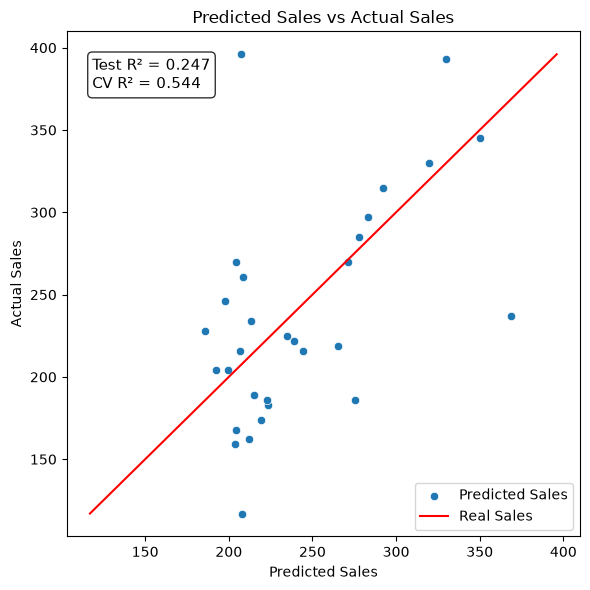

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))

ax.set_title("Predicted Sales vs Actual Sales")
ax.set_xlabel("Predicted Sales")
ax.set_ylabel("Actual Sales")

sns.scatterplot(x=y_pred, y=y_test, ax=ax, label="Predicted Sales")
sns.lineplot(x=y_test, y=y_test, color="red", ax=ax, label="Real Sales")

# Add R² values to the plot
ax.text(
    0.05, 0.95,
    f"Test R² = {r2_test:.3f}\nCV R² = {r2_cross_val.mean():.3f}",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
)

plt.tight_layout()
plt.show()

<Axes: title={'center': 'Predicted Sales vs Actual Sales'}, xlabel='Date', ylabel='Sales'>

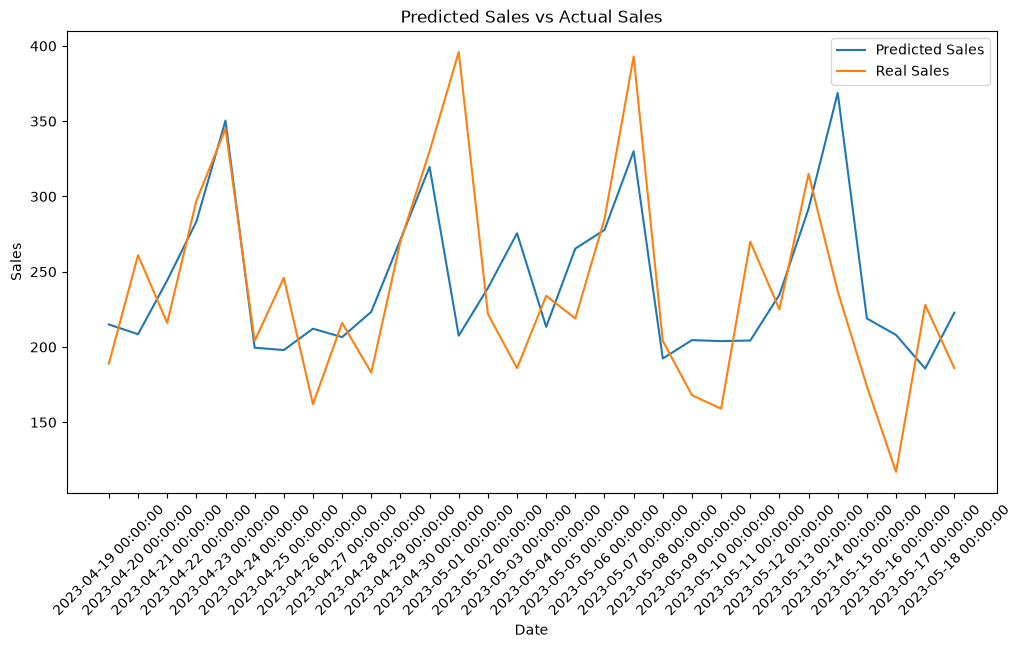

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.set_title("Predicted Sales vs Actual Sales")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.set_xticklabels(df_test["fecha_venta"], rotation=45)

dates = df_test["fecha_venta"].astype(str)
sns.lineplot(x=dates, y=y_pred, label="Predicted Sales")
sns.lineplot(x=dates, y=y_test, label="Real Sales")

### 5.4. Optimize the model

In [ ]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
import mlflow
from sklearn import metrics
import numpy as np

# Small, relevant search space for HistGradientBoostingRegressor
param_distributions = {
    "model__learning_rate": loguniform(0.01, 0.2),
    "model__max_iter": randint(100, 401),
    "model__max_leaf_nodes": randint(15, 64),
    "model__min_samples_leaf": randint(10, 51),
    "model__l2_regularization": loguniform(1e-4, 10),
}

# Time-aware CV with fixed validation windows
tscv = TimeSeriesSplit(n_splits=3, test_size=7)

search = RandomizedSearchCV(
    estimator=final_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    refit=True,
    cv=tscv,
    n_jobs=-1,
    random_state=42,
    verbose=1,
    return_train_score=True,
)

with mlflow.start_run(run_name="HistGradientBoosting_RandomizedSearchCV") as run:

    mlflow.set_tag("product_id", PRODUCT_ID)
    mlflow.set_tag("product_family", PRODUCT_FAMILY)

    mlflow.log_param("model_type", "HistGradientBoostingRegressor")
    mlflow.log_param("optimization_method", "RandomizedSearchCV")
    mlflow.log_param("cv_strategy", "TimeSeriesSplit")
    mlflow.log_param("cv_splits", 3)
    mlflow.log_param("cv_test_size", 7)
    mlflow.log_param("n_iter", 15)
    mlflow.log_param("search_scoring", "neg_mean_absolute_error")
    mlflow.log_param("random_state", 42)

    # Fit the search and obtain the best pipeline
    search.fit(X_train, y_train)
    best_pipeline = search.best_estimator_

    # CV metrics are already available from the search;
    # do not run another cross_val_score pass.
    cv_mae = -search.cv_results_["mean_test_score"][search.best_index_]
    cv_mae_std = search.cv_results_["std_test_score"][search.best_index_]

    # Test predictions and metrics
    y_pred = best_pipeline.predict(X_test)

    r2_test = metrics.r2_score(y_test, y_pred)
    mae_test = metrics.mean_absolute_error(y_test, y_pred)
    rmse_test = metrics.root_mean_squared_error(y_test, y_pred)

    # Log best hyperparameters
    mlflow.log_params({
        f"best_{key}": value
        for key, value in search.best_params_.items()
    })

    mlflow.log_metric("cv_mae_best", cv_mae)
    mlflow.log_metric("cv_mae_best_std", cv_mae_std)
    mlflow.log_metric("r2_test", r2_test)
    mlflow.log_metric("mae_test", mae_test)
    mlflow.log_metric("rmse_test", rmse_test)

    # Log the optimized model
    mlflow.sklearn.log_model(
        sk_model=best_pipeline,
        artifact_path="model",
        serialization_format="cloudpickle",
    )

    print("MLflow run ID:", run.info.run_id)
    print("\nBest parameters:")
    print(search.best_params_)
    print(f"\nBest CV MAE: {cv_mae:.4f}")
    print(f"Test R²:     {r2_test:.4f}")
    print(f"Test MAE:    {mae_test:.4f}")
    print(f"Test RMSE:   {rmse_test:.4f}")


Fitting 3 folds for each of 15 candidates, totalling 45 fits


### 5.5. Plot again the prediction

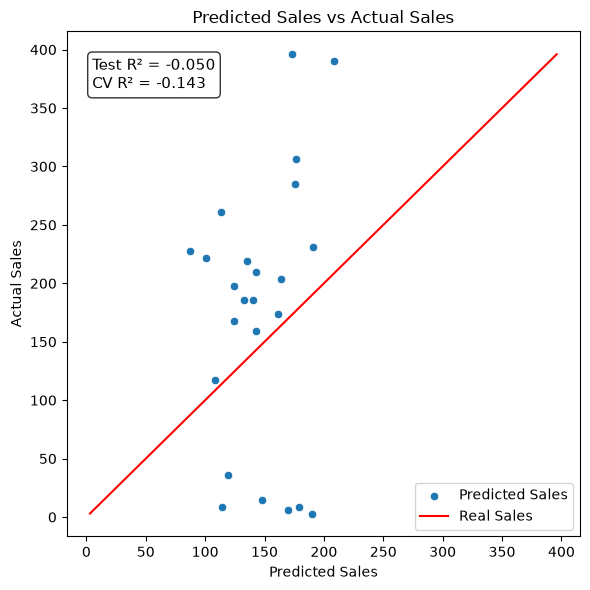

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))

ax.set_title("Predicted Sales vs Actual Sales")
ax.set_xlabel("Predicted Sales")
ax.set_ylabel("Actual Sales")

sns.scatterplot(x=y_pred, y=y_test, ax=ax, label="Predicted Sales")
sns.lineplot(x=y_test, y=y_test, color="red", ax=ax, label="Real Sales")

# Add R² values to the plot
ax.text(
    0.05, 0.95,
    f"Test R² = {r2_test:.3f}\nCV R² = {r2_cross_val.mean():.3f}",
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
)

plt.tight_layout()
plt.show()

<Axes: title={'center': 'Predicted Sales vs Actual Sales'}, xlabel='Date', ylabel='Sales'>

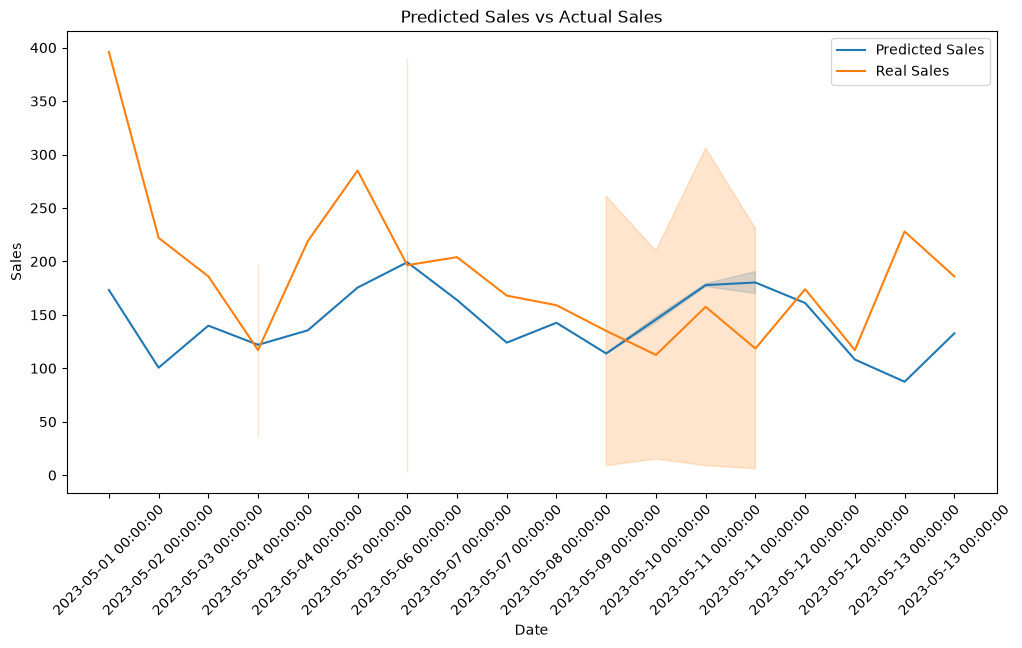

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

ax.set_title("Predicted Sales vs Actual Sales")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.set_xticklabels(df_test["fecha_venta"], rotation=45)

dates = df_test["fecha_venta"].astype(str)
sns.lineplot(x=dates, y=y_pred, label="Predicted Sales")
sns.lineplot(x=dates, y=y_test, label="Real Sales")

## 6. Deploy the model

Check available models

In [41]:
import mlflow
from pprint import pprint

mlflow.set_tracking_uri("http://127.0.0.1:5000")
client = mlflow.MlflowClient()

print("Registered models:")
for model in client.search_registered_models():
    print(model.name)

print("\nVersions of your model:")
for version in client.search_model_versions("name = 'bakery_sales_pred_SVR_25102026'"):
    pprint(dict(version), indent=2)

Registered models:
bakery_3960sales_pred_SVR
bakery_sales_pred_SVR_25102026
bakery_sales_pred_SVR_25102026_v2

Versions of your model:
{ 'aliases': [],
  'creation_timestamp': 1793305971387,
  'current_stage': 'None',
  'deployment_job_state': None,
  'description': '',
  'last_updated_timestamp': 1793305971387,
  'metrics': None,
  'model_id': None,
  'name': 'bakery_sales_pred_SVR_25102026',
  'params': None,
  'run_id': '1fbb60fb88c94a1b89ac1d53abeb6a62',
  'run_link': '',
  'source': 'models:/m-e3762141f33743cab2b908eca1c6131a',
  'status': 'READY',
  'status_message': None,
  'tags': {},
  'user_id': '',
  'version': '3',
  'workspace': 'default'}
{ 'aliases': [],
  'creation_timestamp': 1793303844559,
  'current_stage': 'None',
  'deployment_job_state': None,
  'description': '',
  'last_updated_timestamp': 1793303844559,
  'metrics': None,
  'model_id': None,
  'name': 'bakery_sales_pred_SVR_25102026',
  'params': None,
  'run_id': '9e5e5d4fe10b47d598944c3910420427',
  'run_link


In a terminal run the following command to deploy the model:

```bash
export MLFLOW_TRACKING_URI=http://localhost:5000
mlflow models serve \
  -m "models:/bakery_3960_may_pred_SVR/1" \
  -p 5001 \
  --env-manager local
```

You should see something like this:

```bash
[INFO] Starting gunicorn 21.2.0
[INFO] Listening at: http://127.0.0.1:5001 (236041)
[INFO] Using worker: sync
[INFO] Booting worker with pid: 236048
```

It means it's working correctly 🎉

In [ ]:
import mlflow
from mlflow import MlflowClient

mlflow.set_tracking_uri("http://127.0.0.1:5000")
client = MlflowClient()

print("Getting model version...", flush=True)

version = client.get_model_version(
    name="bakery_3960sales_pred_SVR",
    version="2"
)

print("Model name:", version.name)
print("Version:", version.version)
print("Status:", version.status)
print("Source:", version.source)
print("Run ID:", version.run_id)

Getting model version...
Model name: bakery_3960sales_pred_SVR
Version: 1
Status: READY
Source: models:/m-04446d01a55a4ae68386f7b5f5f2d3c6
Run ID: 608b052b86ca43e88a164446b5788084


## 7. Make requests to the model

The model is now deployed and ready to receive requests. We will make a request to the model using the test set.

- 👉 prepare the test set to be sent as JSON
- 👉 make a POST request to the model
- 👉 get the predictions from the response and show them

In [32]:
import requests
import json


URL = "http://127.0.0.1:5001/invocations"
headers = {"Content-Type": "application/json"}

df_send = df_test.copy()
df_send["fecha_venta"] = df_send["fecha_venta"].astype(str)

data = {
    "dataframe_split": {
        "columns": df_send.columns.tolist(),
        "index": df_send.index.to_list(),
        "data": df_send.values.tolist()
    }
}

response = requests.post(URL, headers=headers, data=json.dumps(data))
predictions = response.json()['predictions']

## 8. Push Results to Database

We push the results to the database so we can visualize them using other tools like Tableau, PowerBI, etc.

Prepare the dataframe to upload to the database

In [33]:
dates = df_send["fecha_venta"].tolist()

# Create a dataframe with the data to store
df_article_prediction = pd.DataFrame({
    "fecha": dates,
    "cantidad": predictions,
    "articulo": [PRODUCT_ID] * len(predictions),  # repeat the article for each date
    "familia": [PRODUCT_FAMILY] * len(predictions),  # repeat the family for each date
})

df_article_prediction.head(5)

,fecha,cantidad,articulo,familia
0,2023-05-01,173.271153,3960,BOLLERIA
1,2023-05-02,100.580348,3960,BOLLERIA
2,2023-05-03,139.890728,3960,BOLLERIA
3,2023-05-04,119.410036,3960,BOLLERIA
4,2023-05-04,124.450932,3960,BOLLERIA


Push the dataframe to the database

In [34]:
# Database credentials
DATABASE = DB_NAME
NAME = USERNAME

table_name = f"Prediction_3960_latest_{NAME}"

# Connect to the database
db = DatabaseConnection(USERNAME, PASSWORD, database=DB_NAME)
db.insert_dataframe(df_article_prediction, table_name)
